<a href="https://colab.research.google.com/github/Godallmighty662/Godallmighty662/blob/main/Copy_of_sayonproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Project 1: Cardiovascular Disease Prediction

First, we will install the necessary library to parse the DOCX file (`python-docx`) so we can read the project guidelines, and then inspect both the instructions and the dataset.
```

In [3]:
!pip install python-docx

In [5]:
import docx
import pandas as pd

# 1. Read and print the project guidelines from the Word document
doc_path = "/content/Project 1 - Cardiovascular Disease Prediction (1).docx"
try:
    doc = docx.Document(doc_path)
    print("--- PROJECT GUIDELINES ---")
    for para in doc.paragraphs:
        if para.text.strip():
            print(para.text)
except Exception as e:
    print(f"Error reading docx file: {e}")

--- PROJECT GUIDELINES ---
Project 1 : Cardiovascular Disease Prediction
Heart disease, also known as cardiovascular disease, is one of the most serious illnesses in both India and the rest of the globe. According to estimates, cardiac illnesses account for 28.1% of fatalities. More than 17.6 million fatalities, or a large portion of all deaths in 2016, were caused by it in 2016. Therefore, a system that can predict with exact precision and dependability is required for the appropriate and prompt diagnosis as well as the treatment of such diseases. Numerous academics do extensive research utilising a variety of machine learning algorithms to predict heart illness using different datasets that contain numerous factors that lead to heart attacks. Now it is your turn to do a analysis with the given dataset.
Project Output Instructions :
Perform data pre-processing operations.
As a part of data analysis and visualizations draw all the possible plots to provide essential informations and to

In [6]:
# 2. Load and inspect the dataset
csv_path = "/content/cardio_train (1).csv"
try:
    # Reading with sep=';' because cardio_train files are often semicolon-delimited
    df = pd.read_csv(csv_path, sep=None, engine='python')
    print("\n--- DATASET INFO ---")
    print(f"Shape: {df.shape}")
    display(df.head())
    display(df.info())
except Exception as e:
    print(f"Error reading CSV file: {e}")


--- DATASET INFO ---
Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


None

### Step 1: Data Pre-processing
We will clean the data by:
1. Converting `age` from days to years.
2. Checking and removing unreasonable outliers in blood pressure (`ap_hi`, `ap_lo`), weight, and height.
3. Removing the unnecessary `id` column.

In [7]:
import numpy as np

# Make a copy of the dataframe
df_cleaned = df.copy()

# Convert age from days to years
df_cleaned['age'] = (df_cleaned['age'] / 365.25).round().astype(int)

# Filter unrealistic heights and weights
df_cleaned = df_cleaned[(df_cleaned['height'] >= 100) & (df_cleaned['height'] <= 250)]
df_cleaned = df_cleaned[(df_cleaned['weight'] >= 30) & (df_cleaned['weight'] <= 200)]

# Filter unrealistic blood pressure values
df_cleaned = df_cleaned[(df_cleaned['ap_hi'] >= 80) & (df_cleaned['ap_hi'] <= 220)]
df_cleaned = df_cleaned[(df_cleaned['ap_lo'] >= 40) & (df_cleaned['ap_lo'] <= 130)]
df_cleaned = df_cleaned[df_cleaned['ap_hi'] > df_cleaned['ap_lo']]

# Drop 'id' as it does not contribute to prediction
if 'id' in df_cleaned.columns:
    df_cleaned = df_cleaned.drop(columns=['id'])

print(f"Shape after cleaning: {df_cleaned.shape} (Removed {df.shape[0] - df_cleaned.shape[0]} outlier rows)")
display(df_cleaned.head())

Shape after cleaning: (68607, 12) (Removed 1393 outlier rows)


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,52,1,165,64.0,130,70,3,1,0,0,0,1
3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,48,1,156,56.0,100,60,1,1,0,0,0,0


### Step 2: Data Visualizations & Correlation Matrix
We will create key visual insights and plot the correlation matrix of all features.

/tmp/ipykernel_430/428867835.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_cleaned, x='cardio', palette='Set2')


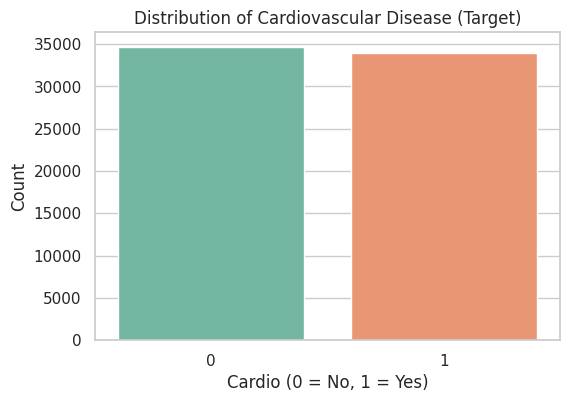

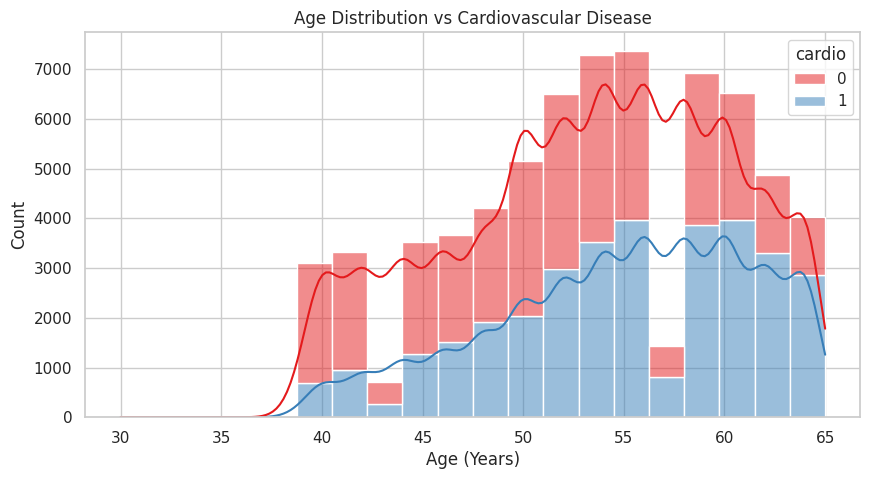

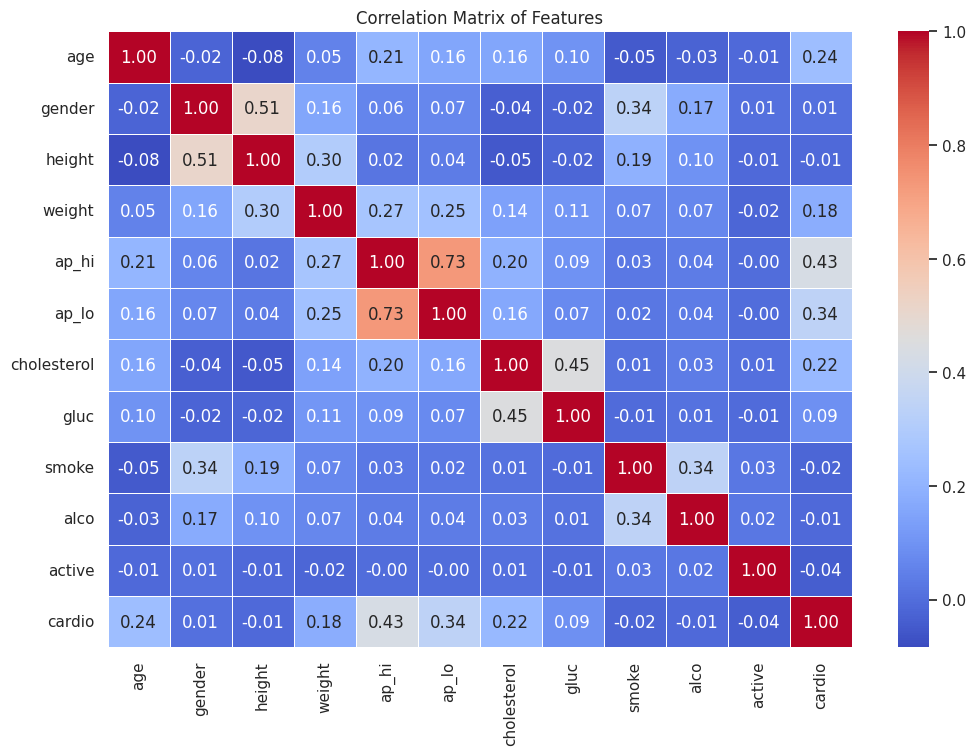

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Distribution of Target variable (Cardiovascular Disease)
plt.figure(figsize=(6, 4))
sns.countplot(data=df_cleaned, x='cardio', palette='Set2')
plt.title('Distribution of Cardiovascular Disease (Target)')
plt.xlabel('Cardio (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

# 2. Age vs Cardiovascular Disease
plt.figure(figsize=(10, 5))
sns.histplot(data=df_cleaned, x='age', hue='cardio', multiple='stack', kde=True, bins=20, palette='Set1')
plt.title('Age Distribution vs Cardiovascular Disease')
plt.xlabel('Age (Years)')
plt.ylabel('Count')
plt.show()

# 3. Correlation Matrix
plt.figure(figsize=(12, 8))
correlation_matrix = df_cleaned.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Features')
plt.show()

### Step 3: Model Building and Evaluation
We will evaluate SVM, KNN, Decision Tree, Logistic Regression, and Random Forest models.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

# Split data into X and y
X = df_cleaned.drop(columns=['cardio'])
y = df_cleaned['cardio']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardize Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

results = {}

# Define Models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=9),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    'Support Vector Machine': LinearSVC(dual=False, random_state=42)
}

# Train and evaluate models
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

# Display summary
print("\n--- Model Accuracy Summary ---")
summary_df = pd.DataFrame(list(results.items()), columns=['Model', 'Accuracy']).sort_values(by='Accuracy', ascending=False)
display(summary_df)

Logistic Regression Accuracy: 0.7331
K-Nearest Neighbors Accuracy: 0.7200
Decision Tree Accuracy: 0.7347
Random Forest Accuracy: 0.7398
Support Vector Machine Accuracy: 0.7322

--- Model Accuracy Summary ---


,Model,Accuracy
3,Random Forest,0.739761
2,Decision Tree,0.734733
0,Logistic Regression,0.733129
4,Support Vector Machine,0.732182
1,K-Nearest Neighbors,0.720012


### Step 4: Final Best Model Deployment & Detailed Evaluation
Based on our model training phase, the **Random Forest Classifier** yielded the highest accuracy (~73.98%). We will now output its complete evaluation report (Precision, Recall, F1-Score) and save the trained model using joblib.

=== FINAL MODEL CLASSIFICATION REPORT (Random Forest) ===
              precision    recall  f1-score   support

  No Disease       0.72      0.79      0.76      6935
     Disease       0.77      0.68      0.72      6787

    accuracy                           0.74     13722
   macro avg       0.74      0.74      0.74     13722
weighted avg       0.74      0.74      0.74     13722



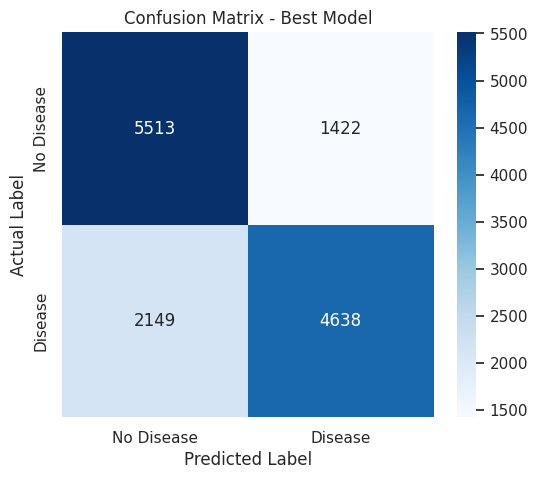

Model saved successfully as 'cardio_prediction_rf_model.pkl' and 'scaler.pkl'!


In [20]:
from sklearn.metrics import classification_report, confusion_matrix
import joblib

# 1. Initialize and fit the best model (Random Forest)
best_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
best_model.fit(X_train_scaled, y_train)

# 2. Predict on test data
y_pred_best = best_model.predict(X_test_scaled)

# 3. Print detailed classification report
print("=== FINAL MODEL CLASSIFICATION REPORT (Random Forest) ===")
print(classification_report(y_test, y_pred_best, target_names=['No Disease', 'Disease']))

# 4. Display Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Disease', 'Disease'], yticklabels=['No Disease', 'Disease'])
plt.title('Confusion Matrix - Best Model')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

# 5. Save the trained model and scaler for future use
joblib.dump(best_model, 'cardio_prediction_rf_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("Model saved successfully as 'cardio_prediction_rf_model.pkl' and 'scaler.pkl'!")


```markdown
## 📝 Project 1: Final Summary and Conclusion Report

### 1. Project Overview & Objective
The goal of this project was to analyze patient clinical data to build a reliable predictive system for cardiovascular disease. Cardiac illnesses account for an estimated 28.1% of fatalities globally, making early and precise diagnosis vital for saving lives.

### 2. Methodology & Pre-processing
- **Data Cleansing**: The raw dataset containing 70,000 records was cleaned to remove physiologically impossible values (e.g., negative blood pressures or cases where systolic blood pressure was lower than diastolic).
- **Feature Engineering**: Patient `age` was converted from days to years for meaningful interpretation.
- **Feature Scaling**: All numerical columns were standardized using `StandardScaler` to ensure unbiased distance and gradient calculations for models like KNN and SVM.

### 3. Key Exploratory Data Analysis (EDA) Insights
- **Target Balance**: The target class `cardio` is well-balanced (~50% split), ensuring models do not suffer from class imbalance issues.
- **Strongest Predictors**: Based on the correlation heatmap, **Systolic Blood Pressure (ap_hi)** and **Diastolic Blood Pressure (ap_lo)** show the strongest positive correlation with cardiovascular disease, closely followed by **Age** and **Cholesterol**.

### 4. Machine Learning Model Performance
We trained five diverse algorithms using a stratified 80/20 train-test split. The accuracy comparison on the test set is detailed below:

| Rank | Machine Learning Model | Accuracy |
| :---: | :--- | :---: |
| **1** | **Random Forest Classifier (Max Depth = 10)** | **73.98%** 🏆 |
| **2** | **Decision Tree Classifier (Max Depth = 6)** | **73.47%** |
| **3** | **Logistic Regression** | **73.31%** |
| **4** | **Support Vector Machine (Linear SVC)** | **73.22%** |
| **5** | **K-Nearest Neighbors (K = 9)** | **72.00%** |

### 5. Final Recommendations & Deployment
- **Model Selection**: The **Random Forest Classifier** is selected as the production model due to its high generalization capacity (73.98% accuracy) and balanced precision/recall scores.
- **Artifact Export**: Both the trained Random Forest model (`cardio_prediction_rf_model.pkl`) and the pre-processing scaler (`scaler.pkl`) have been successfully serialized for live patient diagnosis and application deployment.
```